# Exoplanet detection with a 1D CNN

Can the shape of a phase-folded Kepler light curve improve on a model that uses seven engineered features? We compare a small CNN with and without training augmentation, select one by validation F2, and compare it with a refit of Notebook 01’s MLP on the **same held-out stars**. The logistic models provide additional feature-based baselines.

1. Match light curves and summary features to the original stellar split.
2. Fit the models and choose the CNN and cutoffs using validation data.
3. Compare the frozen models on the shared test set.

## The same stellar split for every model

Start from Notebook 01’s complete cases and stratified split with seed 42. Match each star by `kepid` and retain its original partition. The label comes from the summary table after checking catalog dispositions. Stars with mixed dispositions and inconsistent curve/summary pairs are excluded from **every** model in this notebook. The CSV audits record the reasons.

The MLP has the architecture from Notebook 01 and is refitted here. Both the MLP and the CNN train on the eligible training stars, tune on the eligible validation stars, and predict on the eligible test stars in the same order. Notebook 01’s table describes its original validation split.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

from script.benchmark_data import SEED, prepare_benchmark
from script.train_cnn import CNN_A, CNN_B, augment_residuals, evaluate_test, fit_validation

run_dir = Path("cnn_results/notebook_run")
figure_dir = Path("figures")
figure_dir.mkdir(exist_ok=True)
data = prepare_benchmark(Path("data"), run_dir)

coverage = data.coverage[["original", "retained", "excluded"]].copy()
coverage["class 0 retained"] = [int((data.labels[s] == 0).sum()) for s in coverage.index]
coverage["class 1 retained"] = [int((data.labels[s] == 1).sum()) for s in coverage.index]
display(coverage)
display(data.manifest.loc[~data.manifest.eligible, "exclusion_reason"].value_counts().to_frame("stars"))

,original,retained,excluded,class 0 retained,class 1 retained
split,,,,,
train,748,740,8,548,192
validation,188,186,2,138,48
test,235,233,2,171,62


,stars
exclusion_reason,
mixed_KOI_dispositions,10
curve_summary_mismatch:depth|folded_std|folded_ptp,1
curve_summary_mismatch:depth|folded_std,1


## From light curves to CNN inputs

The preprocessing pipeline centers candidate transits near phase 0.5. Every retained curve has the same **201 phase bins**. The audit checks the phase grid and confirms that the saved period, depth, and folded flux statistics agree with the summary within a 1% relative plus $10^{-7}$ absolute tolerance. The CNN sees flux values ordered by phase.

Divide a curve by its median and subtract one to obtain its relative flux residual $r$. Transform it with $\operatorname{asinh}(r/s)$, where $s$ is the median noise proxy estimated on training stars. The noise proxy uses the median absolute deviation of neighboring flux differences outside the central phase window $|\phi-0.5|\le0.1$. This proxy can include residual variability as well as measurement noise. The transform preserves the sign and ordering of flux changes while compressing the range of deep eclipses.

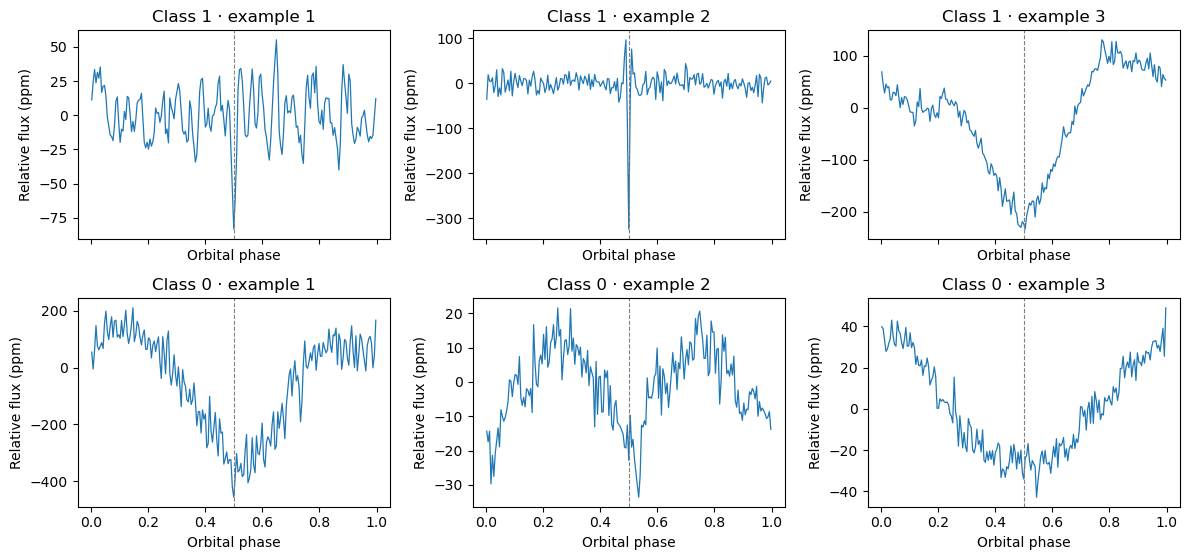

In [2]:
def show_figure(fig, name):
    fig.tight_layout()
    fig.savefig(figure_dir / name, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)


fig, axes = plt.subplots(2, 3, figsize=(12, 5.7), sharex=True)
for label, row in zip([1, 0], axes):
    examples = np.flatnonzero(data.labels["train"] == label)[:3]
    for number, (ax, index) in enumerate(zip(row, examples), 1):
        ax.plot(data.phase, 1e6 * data.residuals["train"][index], lw=0.9)
        ax.axvline(0.5, color="gray", ls="--", lw=0.8)
        ax.set(title=f"Class {label} · example {number}", xlabel="Orbital phase", ylabel="Relative flux (ppm)")
show_figure(fig, "cnn_training_light_curve_examples.png")

## Experiments A and B

Both CNNs use three circular convolution layers with **8, 16, and 16 channels** and kernels of **5, 3, and 3** bins. ReLU follows each convolution. Max pooling follows the first two layers. The final feature maps are averaged into eight phase regions and passed to a 16-unit head with 25% dropout and one output logit. The model has **3,313 trainable parameters**.

| Experiment | Training curves |
|---|---|
| A | Original processed curves |
| B | Random circular shift by −1, 0, or +1 bin and small Gaussian flux perturbations before scaling |

The perturbation scale is 10% of the curve’s noise proxy, capped using the 90th percentile from training. A one-bin shift models small alignment errors. Both CNNs start from identical weights and use the same shuffled sample order. Augmentation is applied to training batches only.

The models use weighted binary cross-entropy with a positive weight set by the training class ratio. CNN training uses AdamW with a learning rate and weight decay of 0.001, batches of 64, and a limit of 120 epochs. We restore the checkpoint chosen by validation loss with a patience of 18 epochs.

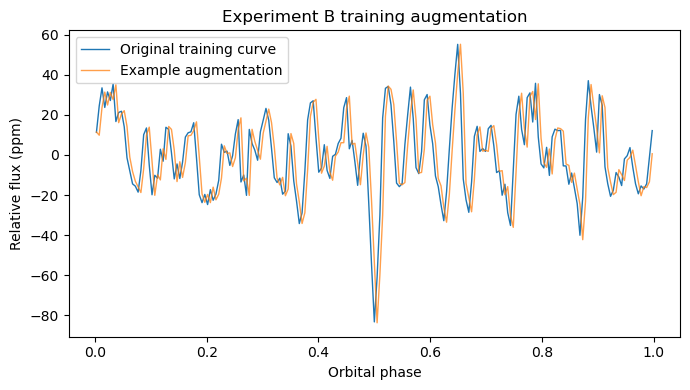

In [3]:
example = int(np.flatnonzero(data.labels["train"] == 1)[0])
original = torch.tensor(data.residuals["train"][[example]], dtype=torch.float32)
sigma = torch.tensor(data.noise["train"][[example]], dtype=torch.float32)
augmented = augment_residuals(original, sigma, data.noise_cap, torch.Generator().manual_seed(SEED + 100))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(data.phase, 1e6 * original[0].numpy(), label="Original training curve", lw=1)
ax.plot(data.phase, 1e6 * augmented[0].numpy(), label="Example augmentation", lw=1, alpha=0.75)
ax.set(xlabel="Orbital phase", ylabel="Relative flux (ppm)", title="Experiment B training augmentation")
ax.legend()
show_figure(fig, "cnn_augmentation_example.png")

### Select the CNN on validation

The refitted MLP uses the same seven summaries and 7 → 16 → 8 → 1 architecture as Notebook 01. Its feature scaler is fitted on the shared training rows. Its shuffled sampler and the CNNs use a dedicated seed of 42.

Each model gets its own cutoff by maximizing **F2** on the shared validation stars. The search uses all attainable cutoffs and chooses the largest in a tie. For CNN A versus B, select the model with higher validation F2, then higher average precision (AP) in a tie, then A. The script saves the chosen CNN, fitted flux scale, and validation cutoffs before the test cell runs.

Validation selected CNN B (augmentation) at cutoff 0.326294.


,Model,N,Threshold,ROC-AUC,AP,Precision,Recall,F2,FP,FN
0,Logistic Regression,186,0.209,0.723,0.421,0.355,0.917,0.696,80,4
1,Weighted Logistic,186,0.437,0.727,0.417,0.367,0.917,0.705,76,4
2,MLP,186,0.363,0.805,0.527,0.412,0.979,0.768,67,1
3,CNN A (no augmentation),186,0.190,0.761,0.552,0.322,1.000,0.704,101,0
4,CNN B (augmentation),186,0.326,0.783,0.552,0.362,0.979,0.730,83,1


,parameters,best_epoch,epochs_run,best_validation_loss
CNN A (no augmentation),3313,48,66,0.845
CNN B (augmentation),3313,78,96,0.801
MLP,273,143,150,0.775


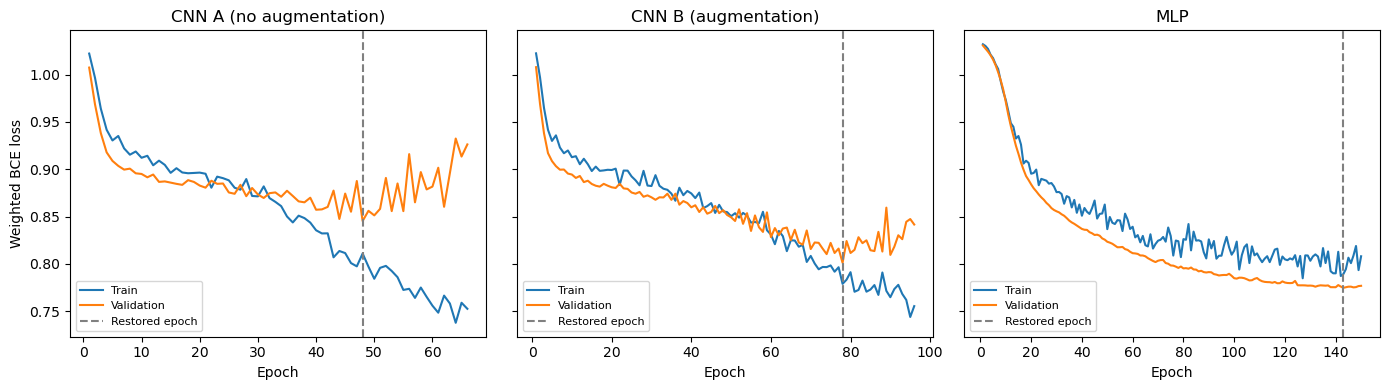

In [4]:
fit = fit_validation(data, run_dir)
metric_columns = ["Model", "N", "Threshold", "ROC-AUC", "AP", "Precision", "Recall", "F2", "FP", "FN"]
display(fit.results[metric_columns].round(3))
training = pd.DataFrame.from_dict(fit.training, orient="index")
display(training[["parameters", "best_epoch", "epochs_run", "best_validation_loss"]].round(3))
print(f"Validation selected {fit.selected_name} at cutoff {fit.thresholds[fit.selected_name]:.6f}.")

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (name, history) in zip(axes, fit.histories.items()):
    ax.plot(history.epoch, history.train_loss, label="Train")
    ax.plot(history.epoch, history.validation_loss, label="Validation")
    ax.axvline(fit.training[name]["best_epoch"], color="gray", ls="--", label="Restored epoch")
    ax.set(xlabel="Epoch", title=name)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Weighted BCE loss")
show_figure(fig, "cnn_mlp_training_histories.png")

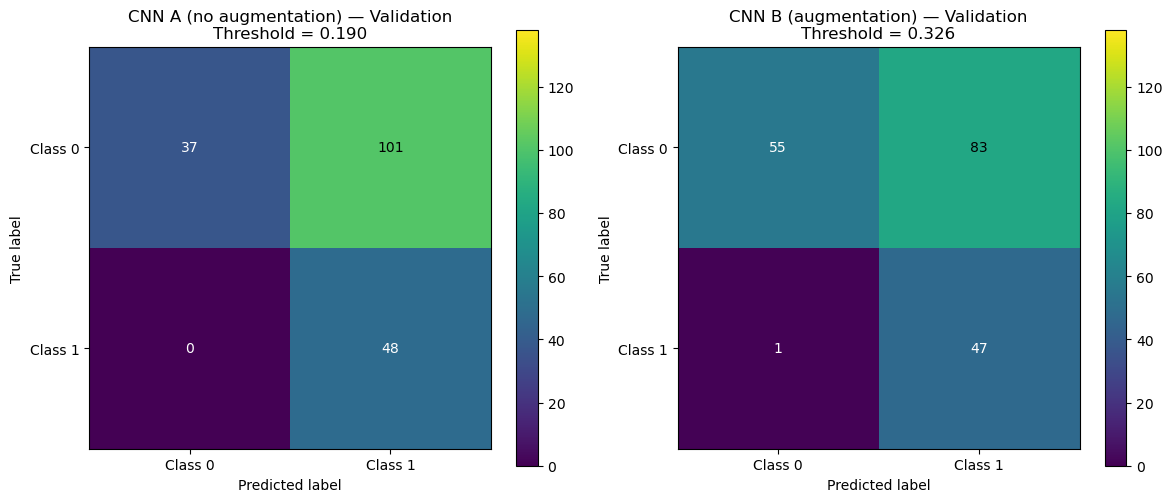

In [5]:
def show_confusions(predictions, names, partition, filename):
    fig, axes = plt.subplots(1, len(names), figsize=(6 * len(names), 5), squeeze=False)
    max_count = int(predictions.label.value_counts().max())
    for name, ax in zip(names, axes[0]):
        threshold = fit.thresholds[name]
        disp = ConfusionMatrixDisplay.from_predictions(
            predictions.label, predictions[name] >= threshold, labels=[0, 1],
            display_labels=["Class 0", "Class 1"], ax=ax, cmap="viridis", values_format="d",
            im_kw={"vmin": 0, "vmax": max_count},
        )
        for label, count in zip(disp.text_.flat, disp.confusion_matrix.flat):
            label.set_color("white" if count < max_count / 2 else "black")
        ax.set_title(f"{name} — {partition}\nThreshold = {threshold:.3f}")
    show_figure(fig, filename)


show_confusions(fit.predictions, [CNN_A, CNN_B], "Validation", "cnn_validation_confusion_matrices.png")

## Held-out test — MLP versus the selected CNN

The validation choices are fixed. The test cell evaluates the selected CNN and the feature baselines once per run. The test prediction table stores one row per `kepid` with a shared true label and a score from each evaluated model. The confusion matrices use each model’s frozen cutoff. A common color scale makes the counts comparable, as in Notebook 01.

Shared test set: 233 stars, including 62 positives.


,Model,N,Threshold,ROC-AUC,AP,Precision,Recall,F2,FP,FN,TP,TN
0,Logistic Regression,233,0.209,0.720,0.551,0.338,0.806,0.631,98,12,50,73
1,Weighted Logistic,233,0.437,0.723,0.554,0.340,0.806,0.633,97,12,50,74
2,MLP,233,0.363,0.770,0.570,0.354,0.903,0.690,102,6,56,69
3,CNN B (augmentation),233,0.326,0.781,0.526,0.367,0.984,0.737,105,1,61,66


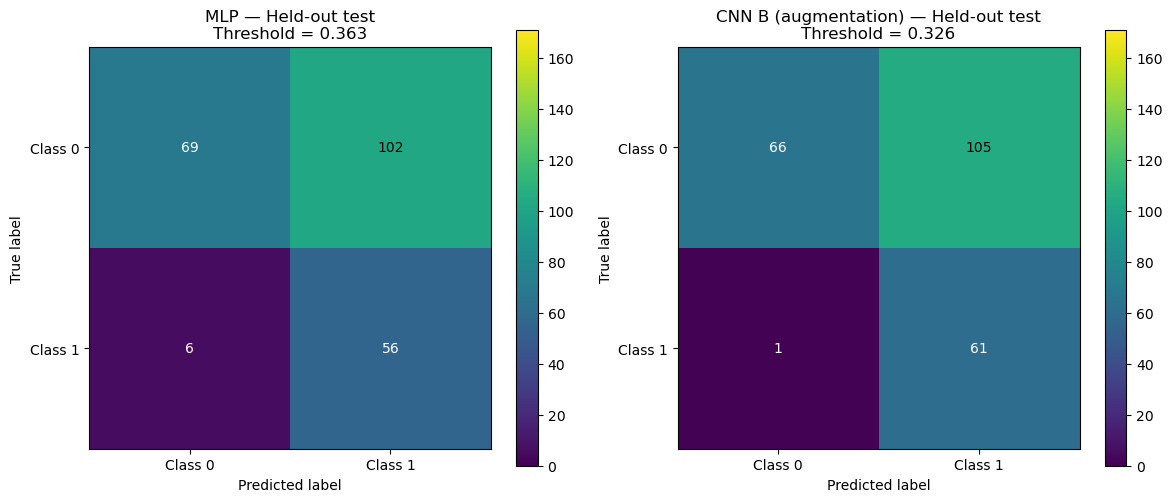

In [6]:
test = evaluate_test(data, fit, run_dir)
assert test.predictions.kepid.tolist() == data.rows["test"].kepid.tolist()
assert set(test.predictions.kepid).isdisjoint(data.rows["train"].kepid)
assert set(test.predictions.kepid).isdisjoint(data.rows["validation"].kepid)

test_models = ["MLP", fit.selected_name]
print(f"Shared test set: {len(test.predictions)} stars, including {int(test.predictions.label.sum())} positives.")
display(test.results[metric_columns + ["TP", "TN"]].round(3))
show_confusions(test.predictions, test_models, "Held-out test", "cnn_mlp_test_confusion_matrices.png")

### Ranking and the screening trade-off

ROC-AUC and AP summarize rankings across cutoffs. The paired intervals resample positive and negative test stars within each class, use the same resampled stars for both models, and keep their validation cutoffs fixed. They describe sampling variation for this split and these fits.

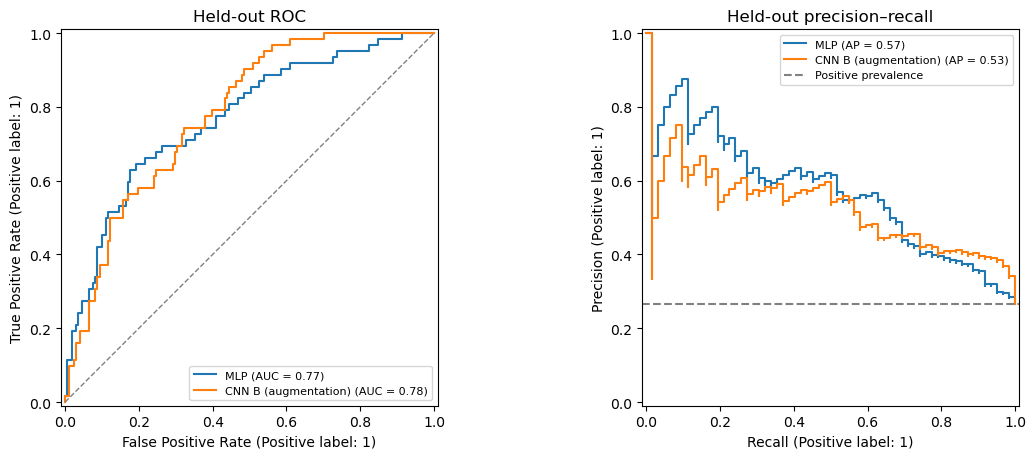

,Difference,CI_low,CI_high,Bootstrap_replicates
Metric,,,,
ROC-AUC,0.0118,-0.0656,0.0907,1000
AP,-0.0433,-0.1760,0.0942,1000
F2,0.0471,-0.0002,0.1007,1000


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
for name in test_models:
    target, scores = test.predictions.label, test.predictions[name]
    RocCurveDisplay.from_predictions(target, scores, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(target, scores, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
axes[1].axhline(test.predictions.label.mean(), ls="--", color="gray", label="Positive prevalence")
axes[0].set_title("Held-out ROC")
axes[1].set_title("Held-out precision–recall")
for ax in axes:
    ax.legend(fontsize=8)
show_figure(fig, "cnn_selected_test_roc_precision_recall.png")

intervals = test.intervals.loc[test.intervals.Comparison == f"{fit.selected_name} minus MLP"].set_index("Metric")
display(intervals[["Difference", "CI_low", "CI_high", "Bootstrap_replicates"]].round(4))

## What the results support

In [8]:
results = test.results.set_index("Model")
cnn, mlp = results.loc[fit.selected_name], results.loc["MLP"]
positives = int(test.predictions.label.sum())
inconclusive = intervals.index[(intervals.CI_low <= 0) & (intervals.CI_high >= 0)].tolist()
display(Markdown(
    f"The CNN found **{int(cnn.TP)} of {positives} positives** and flagged **{int(cnn.FP)} negatives**. "
    f"The MLP found **{int(mlp.TP)} of {positives}** and flagged **{int(mlp.FP)} negatives**. "
    f"The CNN’s F2 was **{cnn.F2:.3f}** against **{mlp.F2:.3f}** for the MLP. "
    f"Their average precisions were **{cnn.AP:.3f}** and **{mlp.AP:.3f}**, respectively. "
    + (f"The paired 95% intervals include zero for {', '.join(inconclusive)}." if inconclusive else "")
))

The CNN found **61 of 62 positives** and flagged **105 negatives**. The MLP found **56 of 62** and flagged **102 negatives**. The CNN’s F2 was **0.737** against **0.690** for the MLP. Their average precisions were **0.526** and **0.570**, respectively. The paired 95% intervals include zero for ROC-AUC, AP, F2.

In this run, the augmented CNN supports a higher-recall screening decision, and the MLP ranks positives better by AP. The paired intervals leave the overall comparison uncertain. Both the input representation and the model architecture change, so the results compare two complete pipelines. The single training seed, small positive test set, and star-level label and curve exclusions limit generalization.

The split manifest, predictions, validation decisions, checkpoint, and full metrics are saved locally under `cnn_results/notebook_run/`. The companion launcher reproduces the same benchmark with `bash execution/run.sh cnn`.